# Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


# Upload dataset

In [3]:
from google.colab import files
uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


# Extract ZIP file

In [4]:
zip_filename = list(uploaded.keys())[0]

raw_folder = "/content/data/raw"
os.makedirs(raw_folder, exist_ok=True)

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(raw_folder)

print("Extraction completed!")

Extraction completed!


# Find CSV files

In [6]:
csv_files = {}

# Using raw_folder which was defined in the extraction step
for root, dirs, filenames in os.walk(raw_folder):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            csv_files[filename.lower()] = os.path.join(root, filename)

print("Available CSV files:")
for filename in csv_files:
    print(filename)

Available CSV files:
customers.csv
products.csv
data_dictionary.csv
orders.csv


#  Preview datasets

In [8]:
# Load the CSV files into DataFrames
orders = pd.read_csv(csv_files['orders.csv'])
customers = pd.read_csv(csv_files['customers.csv'])
products = pd.read_csv(csv_files['products.csv'])
data_dictionary = pd.read_csv(csv_files['data_dictionary.csv'])

print("ORDERS")
display(orders.head())

print("CUSTOMERS")
display(customers.head())

print("PRODUCTS")
display(products.head())

print("DATA DICTIONARY")
display(data_dictionary.head())

ORDERS


,order_item_id,order_id,order_date,customer_id,product_id,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_mode,shipping_fee_gbp,payment_method,order_status,total_revenue_gbp,total_cost_gbp,net_profit_gbp,customer_rating
0,ITEM-01850,ORD-01353,2026-01-01,C-0455,AMZ-4001,1,21.99,0,21.99,Standard Delivery,2.99,Credit/Debit Card,Delivered,24.98,8.0,15.48,NaN
1,ITEM-01526,ORD-01112,2026-01-01,C-0237,AMZ-2001,1,84.99,0,84.99,Standard Delivery,2.99,Credit/Debit Card,Delivered,87.98,36.0,50.48,4.0
2,ITEM-01396,ORD-01017,2026-01-01,C-0454,AMZ-1004,1,39.99,0,39.99,Next-Day Express,4.99,Apple Pay / Digital Wallet,Delivered,44.98,18.0,25.48,3.0
3,ITEM-00371,ORD-00269,2026-01-01,C-0795,AMZ-4002,1,69.99,10,62.99,Standard Delivery,2.99,Apple Pay / Digital Wallet,Delivered,65.98,28.0,36.48,NaN
4,ITEM-03465,ORD-02546,2026-01-01,C-0075,AMZ-3003,1,10.99,10,9.89,Standard Delivery,2.99,Buy Now Pay Later,Delivered,12.88,4.5,6.88,5.0


CUSTOMERS


,customer_id,customer_name,region,is_prime_member,account_created_date
0,C-0001,Sophia Jackson,North West,Yes,2023-09-01
1,C-0002,Zainab Khan,London,No,2025-11-14
2,C-0003,Emily Wilson,Wales,Yes,2023-07-30
3,C-0004,Samuel Wright,South West,Yes,2026-05-15
4,C-0005,Kwame Green,Scotland,Yes,2025-05-11


PRODUCTS


,product_id,product_name,category,sub_category,brand,unit_cost_gbp,list_price_gbp,avg_rating,review_count
0,AMZ-1001,EchoDot-Style Smart Speaker (5th Gen),Electronics,Smart Home,AmzBasics Tech,22.0,49.99,4.7,1420
1,AMZ-1002,Active Noise Cancelling Wireless Headphones,Electronics,Audio,SoundPulse,48.0,119.99,4.5,860
2,AMZ-1003,USB-C 65W Fast Wall Charger GaN,Electronics,Accessories,VoltCore,9.5,24.99,4.6,2150
3,AMZ-1004,4K Ultra HD Streaming Media Stick,Electronics,TV & Video,AmzBasics Tech,18.0,39.99,4.6,1890
4,AMZ-1005,1080p Full HD Webcam with Privacy Cover,Electronics,Computers,ClearView,14.0,34.99,4.3,540


DATA DICTIONARY


,file_name,column_name,data_type,description
0,products.csv,product_id,String (PK),Unique ASIN-style product ID (AMZ-1001 to AMZ-...
1,products.csv,product_name,String,Product title
2,products.csv,category,String,"Top-level marketplace department (Electronics,..."
3,products.csv,sub_category,String,Product sub-category
4,products.csv,brand,String,Brand name


#  Dataset dimensions

In [9]:
print("Orders shape:", orders.shape)
print("Customers shape:", customers.shape)
print("Products shape:", products.shape)
print("Data Dictionary shape:", data_dictionary.shape)

Orders shape: (4352, 17)
Customers shape: (800, 5)
Products shape: (20, 9)
Data Dictionary shape: (31, 4)


#  Column names

In [10]:
for name, df in {
    "Orders": orders,
    "Customers": customers,
    "Products": products
}.items():

    print(f"\n{name} columns:")
    print(df.columns.tolist())


Orders columns:
['order_item_id', 'order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_list_price_gbp', 'discount_pct', 'unit_selling_price_gbp', 'shipping_mode', 'shipping_fee_gbp', 'payment_method', 'order_status', 'total_revenue_gbp', 'total_cost_gbp', 'net_profit_gbp', 'customer_rating']

Customers columns:
['customer_id', 'customer_name', 'region', 'is_prime_member', 'account_created_date']

Products columns:
['product_id', 'product_name', 'category', 'sub_category', 'brand', 'unit_cost_gbp', 'list_price_gbp', 'avg_rating', 'review_count']


#  Data types and information

In [11]:
print("ORDERS INFORMATION")
orders.info()

print("\nCUSTOMERS INFORMATION")
customers.info()

print("\nPRODUCTS INFORMATION")
products.info()

ORDERS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4352 entries, 0 to 4351
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_item_id           4352 non-null   object 
 1   order_id                4352 non-null   object 
 2   order_date              4352 non-null   object 
 3   customer_id             4352 non-null   object 
 4   product_id              4352 non-null   object 
 5   quantity                4352 non-null   int64  
 6   unit_list_price_gbp     4352 non-null   float64
 7   discount_pct            4352 non-null   int64  
 8   unit_selling_price_gbp  4352 non-null   float64
 9   shipping_mode           4352 non-null   object 
 10  shipping_fee_gbp        4352 non-null   float64
 11  payment_method          4352 non-null   object 
 12  order_status            4352 non-null   object 
 13  total_revenue_gbp       4352 non-null   float64
 14  total_cost_gbp       

# Missing values

In [12]:
for name, df in {
    "Orders": orders,
    "Customers": customers,
    "Products": products
}.items():

    print(f"\nMissing values in {name}")
    display(df.isnull().sum())


Missing values in Orders


,0
order_item_id,0
order_id,0
order_date,0
customer_id,0
product_id,0
quantity,0
unit_list_price_gbp,0
discount_pct,0
unit_selling_price_gbp,0
shipping_mode,0



Missing values in Customers


,0
customer_id,0
customer_name,0
region,0
is_prime_member,0
account_created_date,0



Missing values in Products


,0
product_id,0
product_name,0
category,0
sub_category,0
brand,0
unit_cost_gbp,0
list_price_gbp,0
avg_rating,0
review_count,0


#  Duplicate records

In [13]:
print("Orders duplicates:", orders.duplicated().sum())
print("Customers duplicates:", customers.duplicated().sum())
print("Products duplicates:", products.duplicated().sum())

Orders duplicates: 0
Customers duplicates: 0
Products duplicates: 0


#  Descriptive statistics

In [14]:
print("Orders statistical summary")
display(orders.describe(include="all"))

print("Customers statistical summary")
display(customers.describe(include="all"))

print("Products statistical summary")
display(products.describe(include="all"))

Orders statistical summary


,order_item_id,order_id,order_date,customer_id,product_id,quantity,unit_list_price_gbp,discount_pct,unit_selling_price_gbp,shipping_mode,shipping_fee_gbp,payment_method,order_status,total_revenue_gbp,total_cost_gbp,net_profit_gbp,customer_rating
count,4352,4352,4352,4352,4352,4352.000000,4352.000000,4352.000000,4352.000000,4352,4352.000000,4352,4352,4352.000000,4352.000000,4352.000000,1396.000000
unique,4352,3200,304,785,20,NaN,NaN,NaN,NaN,5,NaN,4,3,NaN,NaN,NaN,NaN
top,ITEM-01850,ORD-00973,2026-07-16,C-0137,AMZ-2002,NaN,NaN,NaN,NaN,Next-Day Prime,NaN,Credit/Debit Card,Delivered,NaN,NaN,NaN,NaN
freq,1,3,96,16,339,NaN,NaN,NaN,NaN,1948,NaN,2490,3895,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,1.164982,41.278180,3.786765,39.692116,NaN,0.952123,NaN,NaN,47.160657,19.078814,25.971089,4.143983
std,NaN,NaN,NaN,NaN,NaN,0.433472,34.066458,6.895719,32.987553,NaN,1.566700,NaN,NaN,44.499000,19.378821,25.431105,1.093500
min,NaN,NaN,NaN,NaN,NaN,1.000000,10.990000,0.000000,7.690000,NaN,0.000000,NaN,NaN,7.690000,4.500000,0.690000,1.000000
25%,NaN,NaN,NaN,NaN,NaN,1.000000,18.990000,0.000000,18.990000,NaN,0.000000,NaN,NaN,21.980000,8.000000,11.490000,4.000000
50%,NaN,NaN,NaN,NaN,NaN,1.000000,27.990000,0.000000,27.990000,NaN,0.000000,NaN,NaN,33.240000,12.500000,17.990000,4.000000
75%,NaN,NaN,NaN,NaN,NaN,1.000000,39.990000,5.000000,39.990000,NaN,2.990000,NaN,NaN,49.990000,22.000000,26.980000,5.000000


Customers statistical summary


,customer_id,customer_name,region,is_prime_member,account_created_date
count,800,800,800,800,800
unique,800,530,9,2,623
top,C-0001,Mia Wright,London,Yes,2023-03-11
freq,1,7,171,494,4


Products statistical summary


,product_id,product_name,category,sub_category,brand,unit_cost_gbp,list_price_gbp,avg_rating,review_count
count,20,20,20,20,20,20.000000,20.000000,20.000000,20.000000
unique,20,20,6,20,17,NaN,NaN,NaN,NaN
top,AMZ-1001,EchoDot-Style Smart Speaker (5th Gen),Electronics,Smart Home,AmzBasics Tech,NaN,NaN,NaN,NaN
freq,1,1,5,1,2,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,19.925000,49.790500,4.580000,1521.000000
std,NaN,NaN,NaN,NaN,NaN,17.556881,41.615523,0.160918,1034.117473
min,NaN,NaN,NaN,NaN,NaN,4.500000,10.990000,4.300000,410.000000
25%,NaN,NaN,NaN,NaN,NaN,8.375000,22.740000,4.500000,747.500000
50%,NaN,NaN,NaN,NaN,NaN,13.250000,34.990000,4.600000,1380.000000
75%,NaN,NaN,NaN,NaN,NaN,23.500000,54.990000,4.700000,1897.500000


#  Date range

In [15]:
orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    errors="coerce"
)

print("Start date:", orders["order_date"].min())
print("End date:", orders["order_date"].max())
print("Total days:", orders["order_date"].nunique())

Start date: 2026-01-01 00:00:00
End date: 2026-10-31 00:00:00
Total days: 304


#  Unique values in categorical columns

In [16]:
categorical_columns = [
    "shipping_mode",
    "payment_method",
    "order_status"
]

for column in categorical_columns:
    if column in orders.columns:
        print(f"\n{column}")
        print(orders[column].value_counts(dropna=False))


shipping_mode
shipping_mode
Next-Day Prime       1948
Standard Delivery    1390
Same-Day              530
Next-Day Express      304
Standard              180
Name: count, dtype: int64

payment_method
payment_method
Credit/Debit Card             2490
Apple Pay / Digital Wallet    1060
Gift Card Balance              459
Buy Now Pay Later              343
Name: count, dtype: int64

order_status
order_status
Delivered    3895
Returned      372
Cancelled      85
Name: count, dtype: int64


# Records per month

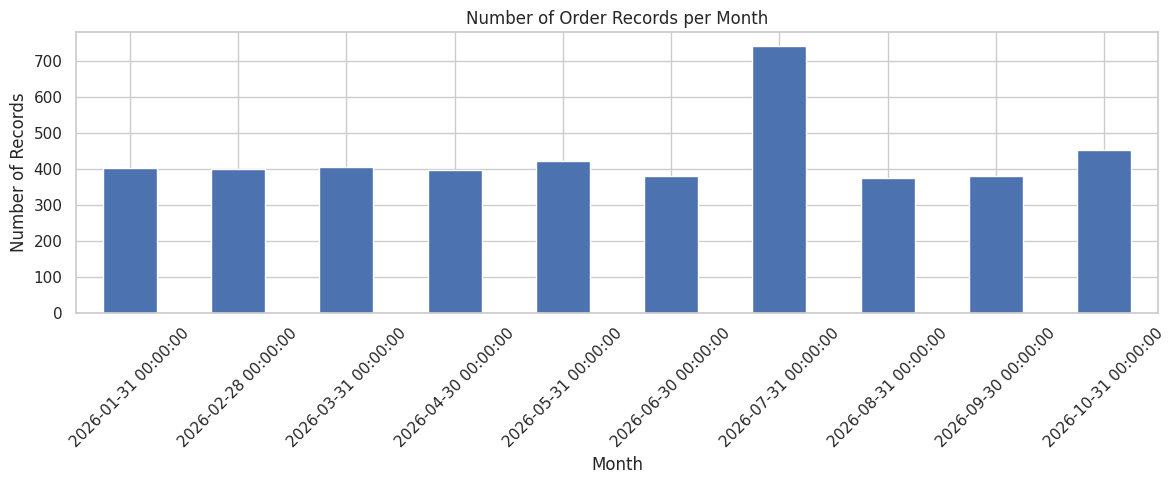

In [17]:
monthly_records = (
    orders.set_index("order_date")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12, 5))
monthly_records.plot(kind="bar")

plt.title("Number of Order Records per Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#  Business scenario

## Business Scenario

An e-commerce business wants to analyze its sales performance, profitability, product performance, customer behavior, and regional performance. The business aims to understand historical sales trends and use forecasting techniques to predict future sales. These insights can support inventory management, marketing decisions, pricing strategies, and business planning.

#  Project objectives

## Project Objectives

- Analyze overall sales and profitability.
- Identify top-performing products and categories.
- Evaluate sales performance across regions.
- Analyze the impact of discounts on revenue and profit.
- Explore customer purchasing patterns.
- Conduct statistical analysis to support business decisions.
- Develop a time-series forecasting model to predict future sales.
- Provide data-driven business recommendations.

#  Business questions

## Business Questions

1. How do sales and revenue change over time?
2. Which products and categories generate the highest revenue?
3. Which regions contribute the most to total revenue and profit?
4. How do discounts affect sales and profitability?
5. Are there statistically significant differences in sales between selected groups?
6. What are the expected sales for the upcoming periods?
7. How can the business improve its sales and profitability?